In [2]:
import torch
from torch import nn
import matplotlib.pyplot as plt

In [10]:
class MassEncoding(nn.Module):
	def __init__(self, resolution):
		super().__init__()
		self.a = nn.Parameter(torch.randn(1, resolution))
		self.b = nn.Parameter(torch.randn(1, resolution))
		self.c = nn.Parameter(torch.randn(1, resolution))

	def forward(self, x, derivative=0):
		z = self.a * x - self.b
		if derivative % 4 == 0:
			y = torch.sin(z)
		elif derivative % 4 == 1:
			y = torch.cos(z)
		elif derivative % 4 == 2:
			y = -torch.sin(z)
		else:
			y = -torch.cos(z)
		return (self.c * self.a.pow(derivative) * y).mean(dim=-1, keepdim=True)

	def compose(self, x, k):
		fix = [self(x)]
		dfix = [self(x, 1)]
		for _ in range(k - 1):
			fix.append(self(fix[-1]))
			dfix.append(self(fix[-1], 1) * dfix[-1])
		return torch.stack(fix), torch.stack(dfix)

In [11]:
mse_loss = nn.MSELoss()

def loss_fn(f, x):
	fx = f(x)
	dfx = f(x, 1)
	return mse_loss(fx, dfx)

def loss_fn(f, x, k):
    _, dfx = f.compose(x, k)
    return mse_loss(dfx[1:], 1.2 * dfx[:-1] + 0.5)

In [12]:
best_device = "cuda" if torch.cuda.is_available() else "cpu"
force_cpu = False
device = best_device if not force_cpu else "cpu"
best_device, device

('cuda', 'cuda')

In [13]:
num_epochs = 100_000
batch_size = 64
resolution = 128
domain = (0, 5)
size_norm = 1.0
size_norm_weight = 0.01
torch.manual_seed(42)

f = MassEncoding(resolution)
f.to(device)
optimizer = torch.optim.Adam(f.parameters(), lr=1e-3)

In [7]:
for i in range(num_epochs):
    x = torch.rand(batch_size, 1, device=device) * (domain[1] - domain[0]) + domain[0]

    size = f(x).abs().mean()
    size_loss = size_norm_weight * (size - size_norm)**2
    target_loss = loss_fn(f, x, 10)

    optimizer.zero_grad()
    (target_loss + size_loss).backward()
    nn.utils.clip_grad_norm_(f.parameters(), 1.0)
    optimizer.step()

    if i % 500 == 0 or i == num_epochs - 1:   
        print(f"{i:5d}  loss {target_loss.item():.6f}  mean|f| {size.item():.6f}")

    0  loss 0.249988  mean|f| 0.064121
  500  loss 0.061804  mean|f| 2.410638
 1000  loss 0.058754  mean|f| 2.586775
 1500  loss 0.058352  mean|f| 2.825556
 2000  loss 0.068464  mean|f| 2.839183
 2500  loss 0.079161  mean|f| 2.350813
 3000  loss 0.056742  mean|f| 2.950171
 3500  loss 0.056873  mean|f| 2.745472
 4000  loss 0.075873  mean|f| 2.782835
 4500  loss 0.081838  mean|f| 2.325078
 5000  loss 0.080791  mean|f| 2.277144
 5500  loss 0.064492  mean|f| 2.346680
 6000  loss 0.057641  mean|f| 2.668438
 6500  loss 0.072393  mean|f| 2.476437
 7000  loss 0.060602  mean|f| 2.905028
 7500  loss 0.061770  mean|f| 2.447625
 8000  loss 0.054017  mean|f| 2.733353
 8500  loss 0.065167  mean|f| 2.607728
 9000  loss 0.077994  mean|f| 2.067200
 9500  loss 0.054896  mean|f| 2.625267
10000  loss 0.059404  mean|f| 2.601966
10500  loss 0.072280  mean|f| 2.364830
11000  loss 0.065627  mean|f| 2.655972
11500  loss 0.078619  mean|f| 2.295069
12000  loss 0.053739  mean|f| 2.567744
12500  loss 0.064971  mea

KeyboardInterrupt: 

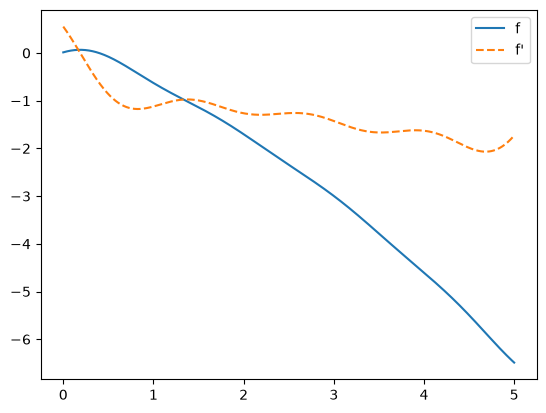

MassEncoding()

In [8]:
f.cpu()
x = torch.linspace(domain[0], domain[1], 1000).unsqueeze(-1)
with torch.no_grad():
    fx = f(x)
    dfx = f(x, 1)

plt.plot(x, fx, label="f")
plt.plot(x, dfx, "--", label="f'")

plt.legend()
plt.show()

f.to(device)

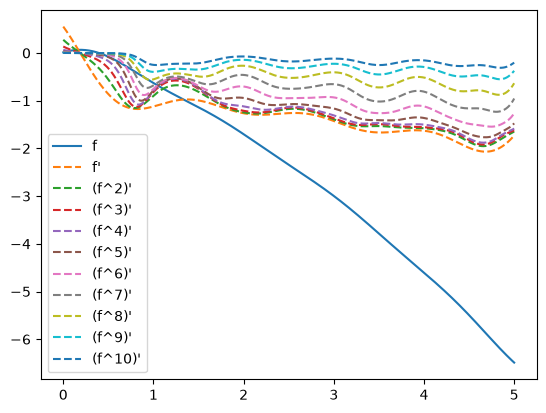

MassEncoding()

In [9]:
f.cpu()
x = torch.linspace(domain[0], domain[1], 1000).unsqueeze(-1)

with torch.no_grad():
    fx, dfx = f.compose(x, 10)

plt.plot(x, fx[0], label="f")
plt.plot(x, dfx[0], "--", label="f'")

for i in range(1, 10):
    plt.plot(x, dfx[i], "--", label=f"(f^{i+1})'")

plt.legend()
plt.show()

f.to(device)